In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
class bsplines:

    def __init__(self, n_basis, degree):

        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 10, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_y = self.knot_vector.clone()

        # 2D trainable coefficients
        self.coeffs = torch.rand(n_basis, n_basis, requires_grad=True)

        # 2D input
        # self.x = x

        # Bsplines for the two dimensions
        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:
            ###########Changes##################
            # return ((x >= knots[i]) & (x < knots[i+1])).float()
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
            ###########Changes##################
        
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x[:,0], self.knot_x ) for i in range(self.n_basis)])
        self.B_y = torch.stack([self.bspline_basis(j, self.degree, x[:,1], self.knot_y) for j in range(self.n_basis)])
        y = torch.zeros(x.shape[0])

        # Because we have Dirichlet BC we just omit the first and last bsplines. If we had BC we should put coeff*Bspline in a different loop 
        # they are not trainable parameteres trainable parameters.
        for i in range(1,(self.n_basis-1)):
            for j in range(1,(self.n_basis-1)):
                y += self.coeffs[i, j] * self.B_x[i]*self.B_y[j]
        

        return y

In [3]:
torch.manual_seed(42)
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# device = torch.device('cpu')

# model = bsplines(10,3)
model = bsplines(20,3)
# model.coeffs.to(device)


In [4]:
p_0 = 0.015
E   = 30000
h   =0.2
nu  =0.2

D   = E*h**3/(12*(1-nu**2))

a = b = 10

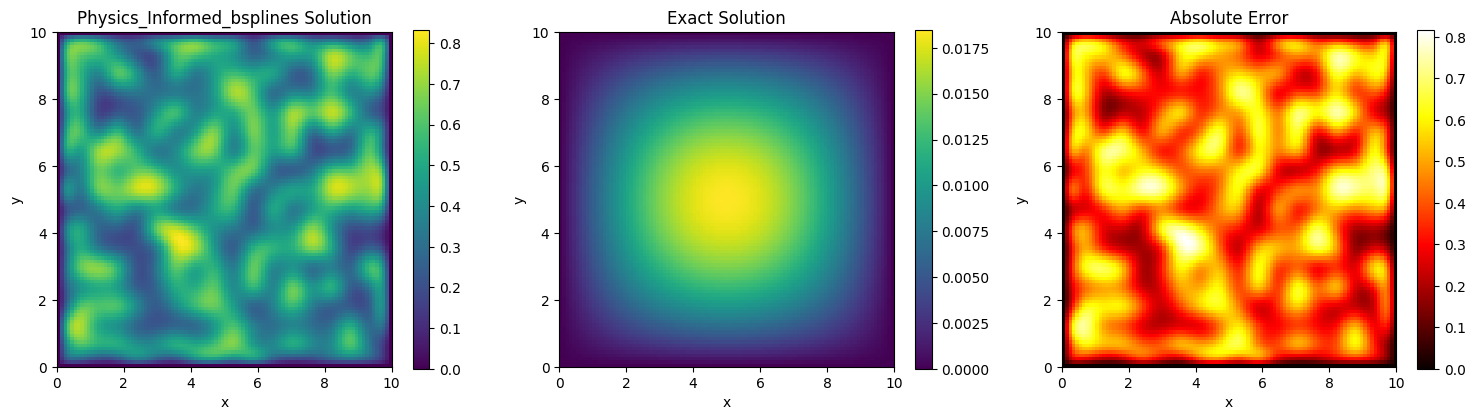

In [5]:
def u_exact(x,y, D, a, b, p_0):
    

    u_ex = p_0/(np.pi**4*D*(1/a**2+1/b**2)**2)*np.sin(x*np.pi/a)*np.sin(y*np.pi/b)

    return u_ex
x = y = np.linspace(0, 10, 100)
Xg, Yg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Yg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
with torch.no_grad():
    u_pred = model.forward(XY_torch).numpy().reshape(Xg.shape)
fig, axs = plt.subplots(1, 3, figsize=(15, 4))

# u_exact = np.sin(np.pi * Xg) * np.sin(np.pi * Yg)
u_ex = u_exact(Xg, Yg, D, a, b, p_0)

# PINN solution
im0 = axs[0].imshow(u_pred, extent=[0,10,0,10], origin='lower', cmap='viridis')
axs[0].set_title("Physics_Informed_bsplines Solution")
fig.colorbar(im0, ax=axs[0])

# Exact solution
im1 = axs[1].imshow(u_ex, extent=[0,10,0,10], origin='lower', cmap='viridis')
axs[1].set_title("Exact Solution")
fig.colorbar(im1, ax=axs[1])

# Absolute error
error = np.abs(u_pred - u_ex)
im2 = axs[2].imshow(error, extent=[0,10,0,10], origin='lower', cmap='hot')
axs[2].set_title("Absolute Error")
fig.colorbar(im2, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()

DC have already been imposed to zero. Now we want to impose Neuman boundary condition:

$m_x(x,y)=-D(\theta_x^2u+\nu\theta_y^2u)$
$\\ m_y(x,y)=-D(\nu\theta_x^2u+\theta_y^2u)$
$\\ m_x(0,y) = m_x(10,y)=m_y(x,0)=m_y(x,10)=0$


$m_x(x,y)=-D(\theta_x^2u+\nu\theta_y^2u)$

$\\ m_x(0,y) = 0$

In [7]:
# impose the first Neumann
torch.manual_seed(42)
X = 10*torch.rand(1000, 2)
X[:,0] = 0.0
X.requires_grad_(True)


tensor([[0.0000, 9.1500],
        [0.0000, 9.5931],
        [0.0000, 6.0090],
        ...,
        [0.0000, 2.4347],
        [0.0000, 7.8342],
        [0.0000, 4.5297]], requires_grad=True)

In [8]:
epochs = 100000
learning_rate=1e-3

optimizer = torch.optim.Adam([model.coeffs], lr=learning_rate)

for epoch in range(epochs):
    
    optimizer.zero_grad()
    
    u = model.forward(X)
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_y = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_yy = torch.autograd.grad(u_y, X, torch.ones_like(u_y), create_graph=True)[0][:, 1]

    # Residual loss
    res = -D*(u_xx+nu*u_yy)
    
    loss = torch.mean(res**2)
    
    loss.backward()
    
    # Manually update parameters using the gradients
    optimizer.step()
    
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')

Epoch [5/100000], Loss: 31684.37890625
Epoch [10/100000], Loss: 30637.935546875
Epoch [15/100000], Loss: 29620.048828125
Epoch [20/100000], Loss: 28632.107421875
Epoch [25/100000], Loss: 27675.01171875
Epoch [30/100000], Loss: 26749.171875
Epoch [35/100000], Loss: 25854.56640625
Epoch [40/100000], Loss: 24990.794921875
Epoch [45/100000], Loss: 24157.1640625
Epoch [50/100000], Loss: 23352.767578125
Epoch [55/100000], Loss: 22576.568359375
Epoch [60/100000], Loss: 21827.4375
Epoch [65/100000], Loss: 21104.234375
Epoch [70/100000], Loss: 20405.826171875
Epoch [75/100000], Loss: 19731.115234375
Epoch [80/100000], Loss: 19079.06640625
Epoch [85/100000], Loss: 18448.71875
Epoch [90/100000], Loss: 17839.16796875
Epoch [95/100000], Loss: 17249.599609375
Epoch [100/100000], Loss: 16679.265625
Epoch [105/100000], Loss: 16127.4765625
Epoch [110/100000], Loss: 15593.599609375
Epoch [115/100000], Loss: 15077.0556640625
Epoch [120/100000], Loss: 14577.302734375
Epoch [125/100000], Loss: 14093.832031

KeyboardInterrupt: 

In [9]:
model.coeffs

tensor([[0.8823, 0.9150, 0.3829, 0.9593, 0.3904, 0.6009, 0.2566, 0.7936, 0.9408,
         0.1332, 0.9346, 0.5936, 0.8694, 0.5677, 0.7411, 0.4294, 0.8854, 0.5739,
         0.2666, 0.6274],
        [0.2696, 0.2014, 0.2518, 0.4445, 0.2236, 0.1377, 0.2869, 0.1972, 0.3253,
         0.0504, 0.2391, 0.0955, 0.2506, 0.3734, 0.2454, 0.3790, 0.3090, 0.3488,
         0.3615, 0.3423],
        [0.6343, 0.6043, 0.7555, 1.3336, 0.6708, 0.4132, 0.8606, 0.5916, 0.9758,
         0.1511, 0.7174, 0.2866, 0.7519, 1.1201, 0.7362, 1.1371, 0.9270, 1.0465,
         1.0845, 0.1447],
        [0.5315, 0.1587, 0.6542, 0.3278, 0.6532, 0.3958, 0.9147, 0.2036, 0.2018,
         0.2018, 0.9497, 0.6666, 0.9811, 0.0874, 0.0041, 0.1088, 0.1637, 0.7025,
         0.6790, 0.9155],
        [0.2418, 0.1591, 0.7653, 0.2979, 0.8035, 0.3813, 0.7860, 0.1115, 0.2477,
         0.6524, 0.6057, 0.3725, 0.7980, 0.8399, 0.1374, 0.2331, 0.9578, 0.3313,
         0.3227, 0.0162],
        [0.2137, 0.6249, 0.4340, 0.1371, 0.5117, 0.1585, 0.0


$m_x(x,y)=-D(\theta_x^2u+\nu\theta_y^2u)$

$\\ m_x(10,y) = 0$

In [10]:
# impose the second Neumann
torch.manual_seed(42)
X = 10*torch.rand(1000, 2)
X[:,0] = 10
X.requires_grad_(True)


tensor([[10.0000,  9.1500],
        [10.0000,  9.5931],
        [10.0000,  6.0090],
        ...,
        [10.0000,  2.4347],
        [10.0000,  7.8342],
        [10.0000,  4.5297]], requires_grad=True)

In [11]:
epochs = 100000
learning_rate=1e-3

optimizer = torch.optim.Adam([model.coeffs], lr=learning_rate)

for epoch in range(epochs):
    
    optimizer.zero_grad()
    
    u = model.forward(X)
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_y = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_yy = torch.autograd.grad(u_y, X, torch.ones_like(u_y), create_graph=True)[0][:, 1]

    # Residual loss
    res = -D*(u_xx+nu*u_yy)
    
    loss = torch.mean(res**2)
    
    loss.backward()
    
    # Manually update parameters using the gradients
    optimizer.step()
    
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')

Epoch [5/100000], Loss: 39539.19140625
Epoch [10/100000], Loss: 38421.703125
Epoch [15/100000], Loss: 37332.79296875
Epoch [20/100000], Loss: 36273.83984375
Epoch [25/100000], Loss: 35245.7890625
Epoch [30/100000], Loss: 34249.0703125
Epoch [35/100000], Loss: 33283.6953125
Epoch [40/100000], Loss: 32349.29296875
Epoch [45/100000], Loss: 31445.171875
Epoch [50/100000], Loss: 30570.43359375
Epoch [55/100000], Loss: 29724.009765625
Epoch [60/100000], Loss: 28904.73828125
Epoch [65/100000], Loss: 28111.3984375
Epoch [70/100000], Loss: 27342.751953125
Epoch [75/100000], Loss: 26597.591796875
Epoch [80/100000], Loss: 25874.73828125
Epoch [85/100000], Loss: 25173.087890625
Epoch [90/100000], Loss: 24491.58203125
Epoch [95/100000], Loss: 23829.26171875
Epoch [100/100000], Loss: 23185.236328125
Epoch [105/100000], Loss: 22558.6953125
Epoch [110/100000], Loss: 21948.904296875
Epoch [115/100000], Loss: 21355.203125
Epoch [120/100000], Loss: 20776.990234375
Epoch [125/100000], Loss: 20213.72460937

KeyboardInterrupt: 

In [12]:
model.coeffs

tensor([[0.8823, 0.9150, 0.3829, 0.9593, 0.3904, 0.6009, 0.2566, 0.7936, 0.9408,
         0.1332, 0.9346, 0.5936, 0.8694, 0.5677, 0.7411, 0.4294, 0.8854, 0.5739,
         0.2666, 0.6274],
        [0.2696, 0.2014, 0.2518, 0.4445, 0.2236, 0.1377, 0.2869, 0.1972, 0.3253,
         0.0504, 0.2391, 0.0955, 0.2506, 0.3734, 0.2454, 0.3790, 0.3090, 0.3488,
         0.3615, 0.3423],
        [0.6343, 0.6043, 0.7555, 1.3336, 0.6708, 0.4132, 0.8606, 0.5916, 0.9758,
         0.1511, 0.7174, 0.2866, 0.7519, 1.1201, 0.7362, 1.1371, 0.9270, 1.0465,
         1.0845, 0.1447],
        [0.5315, 0.1587, 0.6542, 0.3278, 0.6532, 0.3958, 0.9147, 0.2036, 0.2018,
         0.2018, 0.9497, 0.6666, 0.9811, 0.0874, 0.0041, 0.1088, 0.1637, 0.7025,
         0.6790, 0.9155],
        [0.2418, 0.1591, 0.7653, 0.2979, 0.8035, 0.3813, 0.7860, 0.1115, 0.2477,
         0.6524, 0.6057, 0.3725, 0.7980, 0.8399, 0.1374, 0.2331, 0.9578, 0.3313,
         0.3227, 0.0162],
        [0.2137, 0.6249, 0.4340, 0.1371, 0.5117, 0.1585, 0.0


$m_y(x,y)=-D(\nu\theta_x^2u+\theta_y^2u)$

$\\ m_y(x,0) = 0$

In [13]:
# impose the third Neumann
torch.manual_seed(42)
X = 10*torch.rand(1000, 2)
X[:,1] = 0
X.requires_grad_(True)


tensor([[8.8227, 0.0000],
        [3.8286, 0.0000],
        [3.9045, 0.0000],
        ...,
        [0.2557, 0.0000],
        [2.6076, 0.0000],
        [1.7748, 0.0000]], requires_grad=True)

In [14]:
epochs = 100000
learning_rate=1e-3

optimizer = torch.optim.Adam([model.coeffs], lr=learning_rate)

for epoch in range(epochs):
    
    optimizer.zero_grad()
    
    u = model.forward(X)
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_y = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_yy = torch.autograd.grad(u_y, X, torch.ones_like(u_y), create_graph=True)[0][:, 1]

    # Residual loss
    res = -D*(nu*u_xx+u_yy)
    
    loss = torch.mean(res**2)
    
    loss.backward()
    
    # Manually update parameters using the gradients
    optimizer.step()
    
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')

Epoch [5/100000], Loss: 16828.361328125
Epoch [10/100000], Loss: 16152.298828125
Epoch [15/100000], Loss: 15501.2529296875
Epoch [20/100000], Loss: 14876.1640625
Epoch [25/100000], Loss: 14277.3720703125
Epoch [30/100000], Loss: 13704.6318359375
Epoch [35/100000], Loss: 13157.17578125
Epoch [40/100000], Loss: 12633.8291015625
Epoch [45/100000], Loss: 12133.1865234375
Epoch [50/100000], Loss: 11653.779296875
Epoch [55/100000], Loss: 11194.185546875
Epoch [60/100000], Loss: 10753.1396484375
Epoch [65/100000], Loss: 10329.54296875
Epoch [70/100000], Loss: 9922.4580078125
Epoch [75/100000], Loss: 9531.091796875
Epoch [80/100000], Loss: 9154.7587890625
Epoch [85/100000], Loss: 8792.8525390625
Epoch [90/100000], Loss: 8444.833984375
Epoch [95/100000], Loss: 8110.19921875
Epoch [100/100000], Loss: 7788.48193359375
Epoch [105/100000], Loss: 7479.24365234375
Epoch [110/100000], Loss: 7182.0595703125
Epoch [115/100000], Loss: 6896.525390625
Epoch [120/100000], Loss: 6622.25048828125
Epoch [125/1

KeyboardInterrupt: 


$m_y(x,y)=-D(\nu\theta_x^2u+\theta_y^2u)$

$\\ m_y(x,10) = 0$

In [15]:
# impose the fourth Neumann
torch.manual_seed(42)
X = 10*torch.rand(1000, 2)
X[:,1] = 10
X.requires_grad_(True)


tensor([[ 8.8227, 10.0000],
        [ 3.8286, 10.0000],
        [ 3.9045, 10.0000],
        ...,
        [ 0.2557, 10.0000],
        [ 2.6076, 10.0000],
        [ 1.7748, 10.0000]], requires_grad=True)

In [16]:
epochs = 100000
learning_rate=1e-3

optimizer = torch.optim.Adam([model.coeffs], lr=learning_rate)

for epoch in range(epochs):
    
    optimizer.zero_grad()
    
    u = model.forward(X)
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_y = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_yy = torch.autograd.grad(u_y, X, torch.ones_like(u_y), create_graph=True)[0][:, 1]

    # Residual loss
    res = -D*(nu*u_xx+u_yy)
    
    loss = torch.mean(res**2)
    
    loss.backward()
    
    # Manually update parameters using the gradients
    optimizer.step()
    
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')

Epoch [5/100000], Loss: 49204.9765625
Epoch [10/100000], Loss: 47767.7734375
Epoch [15/100000], Loss: 46359.578125
Epoch [20/100000], Loss: 44981.99609375
Epoch [25/100000], Loss: 43636.24609375
Epoch [30/100000], Loss: 42323.1953125
Epoch [35/100000], Loss: 41043.3046875
Epoch [40/100000], Loss: 39796.72265625
Epoch [45/100000], Loss: 38583.36328125
Epoch [50/100000], Loss: 37402.921875
Epoch [55/100000], Loss: 36254.9375
Epoch [60/100000], Loss: 35138.8671875
Epoch [65/100000], Loss: 34054.078125
Epoch [70/100000], Loss: 32999.90625
Epoch [75/100000], Loss: 31975.63671875
Epoch [80/100000], Loss: 30980.548828125
Epoch [85/100000], Loss: 30013.923828125
Epoch [90/100000], Loss: 29075.0234375
Epoch [95/100000], Loss: 28163.1328125
Epoch [100/100000], Loss: 27277.54296875
Epoch [105/100000], Loss: 26417.55078125
Epoch [110/100000], Loss: 25582.470703125
Epoch [115/100000], Loss: 24771.640625
Epoch [120/100000], Loss: 23984.412109375
Epoch [125/100000], Loss: 23220.140625
Epoch [130/1000

KeyboardInterrupt: 

In [17]:
model.coeffs

tensor([[0.8823, 0.9150, 0.3829, 0.9593, 0.3904, 0.6009, 0.2566, 0.7936, 0.9408,
         0.1332, 0.9346, 0.5936, 0.8694, 0.5677, 0.7411, 0.4294, 0.8854, 0.5739,
         0.2666, 0.6274],
        [0.2696, 0.1133, 0.3400, 0.4445, 0.2236, 0.1377, 0.2869, 0.1972, 0.3253,
         0.0504, 0.2391, 0.0955, 0.2506, 0.3734, 0.2454, 0.3790, 0.3090, 0.5327,
         0.1776, 0.3423],
        [0.6343, 0.3400, 1.0199, 1.3336, 0.6708, 0.4132, 0.8606, 0.5916, 0.9758,
         0.1511, 0.7174, 0.2866, 0.7519, 1.1201, 0.7362, 1.1371, 0.9270, 1.5982,
         0.5327, 0.1447],
        [0.5315, 0.2032, 0.6097, 0.3278, 0.6532, 0.3958, 0.9147, 0.2036, 0.2018,
         0.2018, 0.9497, 0.6666, 0.9811, 0.0874, 0.0041, 0.1088, 0.1637, 1.0362,
         0.3454, 0.9155],
        [0.2418, 0.2311, 0.6933, 0.2979, 0.8035, 0.3813, 0.7860, 0.1115, 0.2477,
         0.6524, 0.6057, 0.3725, 0.7980, 0.8399, 0.1374, 0.2331, 0.9578, 0.4905,
         0.1635, 0.0162],
        [0.2137, 0.2647, 0.7942, 0.1371, 0.5117, 0.1585, 0.0

Train the interior points 
$\\ res = \nabla^4u(x,y)-\frac{p(x,y)}{D} = \theta^4w/\theta x^4+2\theta^4w/\theta x^2\theta y^2+\theta^4w/\theta y^4-\frac{p(x,y)}{D}$



In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# impose the third Neumann
torch.manual_seed(42)
X = 10*torch.rand(5000, 2)
X.requires_grad_(True)


tensor([[8.8227, 9.1500],
        [3.8286, 9.5931],
        [3.9045, 6.0090],
        ...,
        [9.2777, 5.7936],
        [8.3082, 2.1809],
        [9.1197, 4.1109]], requires_grad=True)

In [3]:
# model_s = bsplines(20,3)
loaded_params = torch.load('./results/Kirchoff/model_BC_applied.pth')
BC_applied = loaded_params['coeffs_trainable']
BC_applied = BC_applied.detach()


C:\Users\Polydoras\AppData\Local\Temp\ipykernel_30360\1159106907.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_params = torch.load('./results/Kirchoff/model_BC_

In [4]:
class bsplines:

    def __init__(self, n_basis, degree):

        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 10, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_y = self.knot_vector.clone()

        # 2D trainable coefficients
        self.coeffs = torch.zeros(n_basis, n_basis, requires_grad=True)
        self.coeffs_trained = BC_applied
        # 2D input
        # self.x = x

        # Bsplines for the two dimensions
        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:
            ###########Changes##################
            # return ((x >= knots[i]) & (x < knots[i+1])).float()
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
            ###########Changes##################
        
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x[:,0], self.knot_x ) for i in range(self.n_basis)])
        self.B_y = torch.stack([self.bspline_basis(j, self.degree, x[:,1], self.knot_y) for j in range(self.n_basis)])
        y = torch.zeros(x.shape[0])

        # Interior points
        for i in range(3,(self.n_basis-3)):
            for j in range(3,(self.n_basis-3)):
                y += self.coeffs[i, j] * self.B_x[i]*self.B_y[j]

        
        # Left boundary points

        for i in range(1,(self.n_basis-1)):
            for j in range(1,3):

                y += self.coeffs_trained[i, j] * self.B_x[i]*self.B_y[j]
        
        # Right boundary points
        for i in range(1,(self.n_basis-1)):
            for j in range((self.n_basis-3),(self.n_basis-1)):

                y += self.coeffs_trained[i, j] * self.B_x[i]*self.B_y[j]

        #Top boundary points
        for i in range(1,3):
            for j in range(1,(self.n_basis-1)):

                y += self.coeffs_trained[i, j] * self.B_x[i]*self.B_y[j]

        #Top boundary points
        for i in range((self.n_basis-3),(self.n_basis-1)):
            for j in range(1,(self.n_basis-1)):

                y += self.coeffs_trained[i, j] * self.B_x[i]*self.B_y[j]

        

        return y

In [5]:
torch.manual_seed(42)

model = bsplines(20,3)


In [6]:
p_0 = 0.015
E   = 30000
h   =0.2
nu  =0.2

D   = E*h**3/(12*(1-nu**2))

a = b = 10

In [7]:
def source(X):

    p = p_0*torch.sin(np.pi*X[:,0]/a)*torch.sin(np.pi*X[:,1]/b)

    return p

In [6]:
epochs = 100000
learning_rate=1e-3

optimizer = torch.optim.Adam([model.coeffs], lr=learning_rate)

for epoch in range(epochs):
    
    optimizer.zero_grad()
    
    u = model.forward(X)
    # First derivatives
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_y = grads[:, 1]

    # Second derivatives (Laplacian)
    grads2_x = torch.autograd.grad(u_x, X, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    grads2_y = torch.autograd.grad(u_y, X, grad_outputs=torch.ones_like(u_y), create_graph=True)[0]

    u_xx = grads2_x[:, 0]
    u_xy = grads2_x[:, 1]
    u_yy = grads2_y[:, 1]
    u_yx = grads2_y[:, 0]  # should equal u_xy

    laplacian_u = u_xx + u_yy

    # Now compute ∇²(∇²u) = Laplacian of laplacian_u
    laplacian_u_grad = torch.autograd.grad(laplacian_u, X, grad_outputs=torch.ones_like(laplacian_u), create_graph=True)[0]
    laplacian_u_x = laplacian_u_grad[:, 0]
    laplacian_u_y = laplacian_u_grad[:, 1]

    laplacian_u_xx = torch.autograd.grad(laplacian_u_x, X, grad_outputs=torch.ones_like(laplacian_u_x), create_graph=True)[0][:, 0]
    laplacian_u_yy = torch.autograd.grad(laplacian_u_y, X, grad_outputs=torch.ones_like(laplacian_u_y), create_graph=True)[0][:, 1]

    p = source(X)
    # Residual loss
    res = laplacian_u_xx + laplacian_u_yy - p/D
    
    loss = torch.mean(res**2)
    
    loss.backward()
    
    # Manually update parameters using the gradients
    optimizer.step()
    
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')

NameError: name 'X' is not defined

In [ ]:


# Right-hand side of Poisson equation
def f(x, y):
    return -2 * (np.pi ** 2) * torch.sin(np.pi * x) * torch.sin(np.pi * y)

# PDE residual
def pde_loss(model, X):
    X.requires_grad_(True)
    u = model(X)
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_y = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_yy = torch.autograd.grad(u_y, X, torch.ones_like(u_y), create_graph=True)[0][:, 1]
    laplace_u = u_xx + u_yy
    source = f(X[:, 0], X[:, 1])
    return torch.mean((laplace_u - source)**2)

# Boundary loss
def boundary_loss(model, Xb):
    return torch.mean(model(Xb)**2)

# Generate collocation and boundary points
def generate_points(n_interior, n_boundary):
    # Interior points
    xy_in = torch.rand(n_interior, 2).to(device)
    # Boundary points on [0,1]^2
    lin = torch.linspace(0, 1, n_boundary).unsqueeze(1)
    zero = torch.zeros_like(lin)
    one = torch.ones_like(lin)
    b1 = torch.cat([lin, zero], dim=1)
    b2 = torch.cat([lin, one], dim=1)
    b3 = torch.cat([zero, lin], dim=1)
    b4 = torch.cat([one, lin], dim=1)
    xy_b = torch.cat([b1, b2, b3, b4], dim=0).to(device)
    return xy_in, xy_b

# Train the model
###########Changes############
# layers = [2, 20, 20, 20, 1]
# layers = [2, 64, 64, 1]
layers = [2, 86, 86, 1]
###########Changes############

model = PINN(layers).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

###########Changes############
X_in, X_b = generate_points(5000, 1000)
# X_in, X_b = generate_points(5000, 50)
###########Changes############
loss_vec = []
for epoch in range(40000):

    optimizer.zero_grad()

    loss_in = pde_loss(model, X_in)
    loss_b = boundary_loss(model, X_b)
    loss = loss_in + loss_b

    loss.backward()
    optimizer.step()

    loss_vec.append(loss.item())
    if epoch % 300 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.6f}")
    # if epoch==0:
    #     break  


